# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: NOMBRE DEL GRUPO

# Integrantes
* integrante
* integrante

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import cv2
import alc

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Sabemos que Q es una transformación lineal que va de R^12 a R^2n. Además dim(Im(Q)) = Rango(Q). Además nos piden que dim(Nu(Q)) = 1. Usando el teroema de la dimensión sabemos que:

dim(R^12) = dim(Im(Q)) + dim(Nu(Q)) => 12 = Rango(Q) + 1 => Rango(Q) = 11


Puntos mínimos para asegurar solución: Cada punto genera 2 filas de la matriz. Debido a que necesitamos que la matriz tenga rango 11 necesitamos al menos 6 puntos, de los cuales al menos 5 generen filas LI, y tiene que haber al menos 1 que genere una fila LD.


Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

Normalmente no existe un vector no nulo que satisfaga exactamente $Qm = 0$, lo que nos lleva a reemplazar la igualdad exacta a plantear la minimización:

$$\min_{\mathbf{m}} \|Q\mathbf{m}\|^2, \text{ sujeto a } \|\mathbf{m}\| = 1$$

lo que equivale a

$$\min_{\|\mathbf{m}\| = 1} \|Q\mathbf{m}\|^2 = \min_{\|\mathbf{m}\| = 1} (Q\mathbf{m})^T (Q\mathbf{m}) = \min_{\|\mathbf{m}\| = 1} \mathbf{m}^T Q^T Q\mathbf{m}$$

Planteamos la descomposición SVD de Q:

$$Q = U\Sigma V^T$$

con $U\in\R^{2n \times 2n}$, $V\in\R^{12 \times 12}$ matrices ortogonales y $\Sigma \in\R^{2n \times 12}$ una matriz _pseudo-diagonal_ con $\sigma_i = \Sigma_{ii}$ tales que $\sigma_1 \geq \sigma_2 \geq \dots \geq \sigma_r \geq 0$, siendo $r = \min(2n,12)$. Por el inciso $1)a)$, nos interesa el caso $2n \geq 12$, con lo cual podemos tomar $r = 12$. Entonces,

$$\begin{aligned}
    &\ \mathbf{m}^T Q^T Q\mathbf{m} \\
    &= \mathbf{m}^T (U \Sigma V^T)^T (U \Sigma V^T)\mathbf{m} \\
    &= \mathbf{m}^T (V \Sigma^T U^T) (U \Sigma V^T)\mathbf{m} \\
    &= \mathbf{m}^T V \Sigma^T \Sigma V^T\mathbf{m} \\
\end{aligned}$$

donde usamos que $U^T U = I$, por ser $U$ ortogonal.

Ahora, como $V\in\R^{12 \times 12}$ es ortogonal, sabemos que sus columnas forman una base ortonormal de $\R^{12}$. Como $\mathbf{m}\in\R^{12}$, podemos escribir a $\mathbf{m}$ como combinación lineal de las columnas de $V$:

$$\mathbf{m} = \alpha_1 v_1 + \dots + \alpha_{12} v_{12}$$

o equivalentemente

$$\mathbf{m} =
\left(\begin{array}{c|c|c|c}
v_1 & v_2 & \cdots & v_{12}
\end{array}\right)
\begin{pmatrix} \alpha_1 \\ \alpha_2 \\ \vdots \\ \alpha_{12} \end{pmatrix}
= V C$$

definimos entonces $C$ como el "vector de coeficientes". Por lo tanto nos quedaría:

$$\begin{aligned}
    & \mathbf{m}^T V \Sigma^T \Sigma V^T\mathbf{m} \\
    &= (V C)^T V \Sigma^T \Sigma V^T(V C) \\
    &= C^T V^T V \Sigma^T \Sigma V^T V C \\
    &= C^T I \Sigma^T \Sigma I C \\
    &= C^T  \Sigma^T \Sigma C \\
\end{aligned}$$

por ser $V$ ortogonal. 

Observemos que $\Sigma^T\in\R^{12 \times 2n}$ y $\Sigma\in\R^{2n \times 12}$, con lo cual $\Sigma^T \Sigma \in \R^{12 \times 12}$ y:

$$(\Sigma^T \Sigma)_{ij} = \sum_{k=1}^{2n} (\Sigma^T)_{ik} \Sigma_{kj} = \sum_{k=1}^{2n} \Sigma_{ki} \Sigma_{kj}$$

Como $\Sigma$ es pseudo-diagonal, $\Sigma_{ki} = 0$  $\forall k \neq i$, con lo cual el único término no nulo de la suma es el de $k = i$, y lo mismo con $j$. Entonces, para $1 \leq i \leq 12$, solo sobreviven los términos $\Sigma_{ii} \Sigma_{ii} = \sigma_{i} \sigma_{i} = \sigma_{i}^2$, es decir:

$$(\Sigma^T \Sigma)_{ij} =
\begin{cases}
    \sigma_i^2 & \text{si } i = j \\
    0          & \text{si } i \neq j
\end{cases}$$

i.e. $\Sigma^T \Sigma = \operatorname{diag}(\sigma_1^2, \sigma_2^2, \dots, \sigma_{12}^2) \in \R^{12 \times 12}$.

Por lo tanto, la multiplicacion nos quedaría algo como

$$\begin{aligned}
    & C^T \Sigma^T \Sigma C \\
    &= 
        \begin{pmatrix} \alpha_1 & \alpha_2 & \cdots & \alpha_{12} \end{pmatrix}
        \begin{pmatrix}
            \sigma_1^2 &        &        &            \\
                      & \sigma_2^2 &    &            \\
                      &        & \ddots &            \\
                      &        &        & \sigma_{12}^2
        \end{pmatrix}
        \begin{pmatrix} \alpha_1 \\ \alpha_2 \\ \vdots \\ \alpha_{12} \end{pmatrix} \\
    &= \begin{pmatrix} \alpha_1 & \alpha_2 & \cdots & \alpha_{12} \end{pmatrix}
       \begin{pmatrix} \alpha_1 \sigma_1^2 \\ \alpha_2 \sigma_2^2 \\ \vdots \\ \alpha_{12} \sigma_{12}^2 \end{pmatrix} \\
    &= \alpha_1^2 \sigma_1^2 + \alpha_2^2 \sigma_2^2 + \dots + \alpha_{12}^2 \sigma_{12}^2
\end{aligned}$$


Con lo cual llegamos a que vale:

$$\begin{aligned}
&\min_{\|\mathbf{m}\| = 1} \|Q\mathbf{m}\|^2 \\
&= \min_{\|\mathbf{m}\| = 1} \mathbf{m}^T Q^T Q\mathbf{m} \\
&= \min_{\|\mathbf{m}\| = 1} \alpha_1^2 \sigma_1^2 + \alpha_2^2 \sigma_2^2 + \dots + \alpha_{12}^2 \sigma_{12}^2 \\
&= \min_{\|\mathbf{m}\| = 1} \ \sum_{i=1}^{12} \sigma_i^2 \alpha_i^2
\end{aligned}$$

Veamos ahora que nos dice la restricción $\|\mathbf{m}\| = 1$. Recordemos que pudimos definir $m$ como

$$\mathbf{m} = \alpha_1 v_1 + \dots + \alpha_{12} v_{12} = V C$$

Entonces,

$$\|\mathbf{m}\|^2 = \mathbf{m}^T \mathbf{m} = (V C)^T (V C) = C^T V^T V C$$

Como $V$ es ortogonal:

$$\|\mathbf{m}\|^2 = C^T V^T V C = C^T I C = C^T C = \|C\|^2$$

con lo cual $\|\mathbf{m}\| = 1 \iff \|C\| = 1 \iff \alpha_1^2 + \alpha_2^2 + \dots + \alpha_{12}^2 = 1$. 

El problema original resulta entonces equivalente a

$$\min_{\|C\| = 1} \ \sum_{i=1}^{12} \sigma_i^2 \alpha_i^2$$

Recordemos tambien que los valores singulares están ordenados $\sigma_1 \geq \sigma_2 \geq \dots \geq \sigma_{12} \geq 0$, con lo cual $\sigma_i^2 \geq \sigma_{12}^2$ para todo $i$, entonces podemos acotar inferiormente la suma de la siguiente manera
$$\sum_{i=1}^{12} \sigma_i^2 \alpha_i^2 \geq \sum_{i=1}^{12} \sigma_{12}^2 \alpha_i^2 = \sigma_{12}^2 \sum_{i=1}^{12} \alpha_i^2 \underset{\scriptstyle \|C\|_2 = 1}{=} \sigma_{12}^2$$

Es decir, $\sigma_{12}^2$ es una cota inferior del valor a minimizar. 

$$
\min_{\|\mathbf{m}\| = 1} \|Q\mathbf{m}\|^2 
= \min_{\|C\| = 1} \ \sum_{i=1}^{12} \sigma_i^2 \alpha_i^2 
\geq \sigma_{12}^2 
$$

Pero si tomamos $\alpha_{12} = 1$ y $\alpha_i = 0$ para $i \neq 12$ (es decor, $C = e_{12}$, que cumple $\|C\| = 1$) obtenemos

$$\sum_{i=1}^{12} \sigma_i^2 \alpha_i^2 = \sigma_1^2 \cdot 0 + \sigma_2^2 \cdot 0 + \dots + \sigma_{11}^2 \cdot 0 + \sigma_{12}^2 \cdot 1 = \sigma_{12}^2$$

Por lo tanto el mínimo vale exactamente $\sigma_{12}^2$ y se alcanza tomando $C = e_{12}$:

$$
\min_{\|\mathbf{m}\| = 1} \|Q\mathbf{m}\|^2 
= \min_{\|C\| = 1} \ \sum_{i=1}^{12} \sigma_i^2 \alpha_i^2 
\underset{\scriptstyle C = e_{12}}{=} \sigma_{12}^2 
$$

Por lo tanto:

$$\mathbf{m} = V C = V e_{12} = v_{12}$$

o sea, **$\mathbf{m}$ es la última columna de $V$**: el vector singular derecho asociado al menor valor singular de $Q$.

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

# Emprolijar explicación 2.C
Para calcular R, t y K a partir de M tomamos que M = K [R | t] = [KR | Kt]. Tomamos M_3 las primeras 3 filas y columnas de M entonces M_3 = KR .teniendo en cuenta que K es triangular superior y R es ortonormal se ve que parece una descomposicion QR invertida. Tomamos la inversa entonces (M_3)^-1 = R^-1 * K^-1 = R^T * K^-1 por R ser ortonormal. Además como K es triangular superior su inversa tambien lo es. Entonces R^T K^-1 es una descomposición QR de M_3^-1 donde R^T = Q y K^-1 es U (U sería la R en la decomp QR)

Además sabemos que M_4 = Kt (M_4 es el vector correspondiente a la cuarta columna de M) entonces tenemos algo de la forma Ax = B, siendo A triangular superior.


Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

#### Resolución 3

**Datos.** En cada vista marcamos a mano las 4 esquinas internas extremas del tablero. En el plano del tablero son $(0, 0)$, $(300, 0)$, $(0, 180)$ y $(300, 180)$ mm, porque las esquinas internas están en $(30i,\ 30j)$ con $i = 0..10$, $j = 0..6$. Quedaron guardadas en $\texttt{p\_corners.txt}$ (mm) y $\texttt{detected\_corners.txt}$ (px, una fila por vista).

En la carpeta $\texttt{calib/coplanar}$ hay 10 imágenes ($\texttt{Im\_R\_1}$ a $\texttt{Im\_R\_10}$), no 20, así que trabajamos con esas 10.

In [2]:
filepath_calib = 'calib/coplanar'

objPts_tablero = np.loadtxt(f'{filepath_calib}/p_corners.txt')
imgPts_vistas = np.loadtxt(f'{filepath_calib}/detected_corners.txt')
print(objPts_tablero)
print(imgPts_vistas.shape)

[[  0.   0.]
 [300.   0.]
 [  0. 180.]
 [300. 180.]]
(10, 8)


**Homografía de cada vista.** Como el tablero es plano ($W = 0$), cada vista queda descripta por una homografía $\mathbf{H}$ de 3×3 con 8 grados de libertad. Cada punto aporta 2 ecuaciones, así que alcanzan 4 puntos sin 3 alineados para que $Q \in \mathbb{R}^{8\times 9}$ tenga rango 8. La calculamos con $\texttt{resolverDLT2D}$ (DLT con normalización de Hartley).

In [3]:
Hs = []
for k in range(imgPts_vistas.shape[0]):
    imgPts_k = imgPts_vistas[k].reshape(-1, 2)
    Hs.append(alc.resolverDLT2D(imgPts_k, objPts_tablero))
print(len(Hs), 'homografías')

10 homografías


**a) Matriz $\mathbf{K}$ (Zhang).** Cada $\mathbf{H} = \lambda \mathbf{K}[\mathbf{r}_1\ \mathbf{r}_2\ \mathbf{t}]$. Como $\mathbf{r}_1$ y $\mathbf{r}_2$ son ortonormales, con $\mathbf{B} = \mathbf{K}^{-T}\mathbf{K}^{-1}$ y $\mathbf{h}_i$ las columnas de $\mathbf{H}$:

$$\mathbf{h}_1^T \mathbf{B}\, \mathbf{h}_2 = 0, \qquad \mathbf{h}_1^T \mathbf{B}\, \mathbf{h}_1 = \mathbf{h}_2^T \mathbf{B}\, \mathbf{h}_2.$$

$\mathbf{B}$ es simétrica, así que tiene 6 incógnitas $\mathbf{b}$, y cada vista da 2 ecuaciones $\mathbf{v}_{12}^T\mathbf{b} = 0$ y $(\mathbf{v}_{11} - \mathbf{v}_{22})^T\mathbf{b} = 0$. Con las 10 vistas armamos $A \in \mathbb{R}^{20\times 6}$ ($\texttt{armarA}$) y resolvemos $\min_{\|\mathbf{b}\|=1} \|A\mathbf{b}\|$.

Después, con Cholesky $\mathbf{B} = \mathbf{L}\mathbf{L}^T$, obtenemos $\mathbf{K} = (\mathbf{L}^T)^{-1}$ y la normalizamos para que $K_{33} = 1$ ($\texttt{calcularMatrizK2D}$). Como $\mathbf{b}$ sale a menos de un signo, si $\mathbf{B}$ no es definida positiva la multiplicamos por $-1$.

In [4]:
A = alc.armarA(Hs)
K = alc.calcularMatrizK2D(A)
print(K)

[[902.74402928   0.93859449 535.00195547]
 [  0.         918.73610294 284.54069293]
 [  0.           0.           1.        ]]


El centro óptico $(c_u, c_v) \approx (535,\ 285)$ queda cerca del centro de la imagen ($1024 \times 576$ px, centro en $(512,\ 288)$), y $\alpha_u \approx \alpha_v$. El término $K_{12}$ (skew) es chico comparado con las focales.

**b) Pose de $\texttt{Im\_R\_1}$ y $\texttt{Im\_R\_10}$.** De $\mathbf{H} = \lambda\mathbf{K}[\mathbf{r}_1\ \mathbf{r}_2\ \mathbf{t}]$:

$$\lambda = \frac{1}{\|\mathbf{K}^{-1}\mathbf{h}_1\|}, \quad \mathbf{r}_1 = \lambda \mathbf{K}^{-1}\mathbf{h}_1, \quad \mathbf{r}_2 = \lambda \mathbf{K}^{-1}\mathbf{h}_2, \quad \mathbf{r}_3 = \mathbf{r}_1 \times \mathbf{r}_2, \quad \mathbf{t} = \lambda \mathbf{K}^{-1}\mathbf{h}_3$$

($\texttt{obtenerPose2D}$). $\mathbf{t}$ queda en mm, igual que los puntos del tablero. $\texttt{Im\_R\_20}$ no está en la carpeta.

In [5]:
for k in [0, 9]:
    R, t = alc.obtenerPose2D(Hs[k], K)
    print(f'Im_R_{k + 1}')
    print('R =')
    print(R)
    print('t =', t)
    print()

Im_R_1
R =
[[ 0.99952023 -0.01172614 -0.0275736 ]
 [ 0.01423676  0.99777562  0.00866082]
 [ 0.02750683 -0.00898768  0.99746386]]
t = [-120.56426632 -131.36099801  668.47030125]

Im_R_10
R =
[[ 0.99688397  0.06839674 -0.03639238]
 [-0.06166592  0.9799015   0.19426785]
 [ 0.04919006 -0.19150013  0.98106585]]
t = [-106.78764093 -143.79615568  652.26754081]


### Ejercicio 4 - Fútbol

a) Calcular la distancia en línea recta, medida sobre el piso, a la que se encuentra Enzo de la línea del arco cuando patea al gol. Para ello, llevar la posición de sus pies de la imagen a la cancha mediante $\mathbf{H}^{-1}$.

#### Resolución 4.a

**Sistema de coordenadas.** Tomamos el sistema del plano $\texttt{estadio\_azteca.png}$: origen en la esquina inferior izquierda, $U$ a lo largo de la cancha ($0$ a $105$ m) y $V$ a lo ancho ($0$ a $68$ m). En la foto, Enzo patea hacia el arco de $U = 0$. Como la cámara mira hacia ese arco desde adentro de la cancha, lo que en la foto está a la izquierda tiene $V$ menor.

**Puntos de referencia.** Para estimar $\mathbf{H}$ necesitamos puntos del **piso** cuya posición conozcamos tanto en la cancha (metros) como en la foto (píxeles). Elegimos 7:

| # | Punto | $(U, V)$ [m] | $(u, v)$ [px] |
|---|---|---|---|
| 0 | Base del palo izquierdo | $(0,\ 30.34)$ | $(388,\ 176)$ |
| 1 | Base del palo derecho | $(0,\ 37.66)$ | $(652,\ 184.5)$ |
| 2 | Área chica, esquina frontal izquierda | $(5.5,\ 24.84)$ | $(157,\ 231)$ |
| 3 | Área chica, esquina frontal derecha | $(5.5,\ 43.16)$ | $(867,\ 250)$ |
| 4 | Punto penal | $(11,\ 34)$ | $(511,\ 317)$ |
| 5 | Medialuna $\cap$ línea del área, izquierda | $(16.5,\ 26.69)$ | $(146,\ 406)$ |
| 6 | Medialuna $\cap$ línea del área, derecha | $(16.5,\ 41.31)$ | $(851,\ 422)$ |

Las coordenadas en metros salen del plano: el arco mide $7.32$ m (palos en $V = 34 \pm 3.66$), el área chica $5.5 \times 18.32$ m ($V = 34 \pm 9.16$), el penal está a $11$ m y la línea del área grande en $U = 16.5$. Las coordenadas en píxeles se marcaron a mano sobre la imagen, tomando el centro de las líneas blancas y la base de los palos.

Para los puntos 5 y 6 nos ayudamos con el **reglamento** (IFAB, Regla 1): la medialuna es un arco de radio $9.15$ m centrado en el penal. El plano la dibuja pero no indica su radio, que es consistente con lo dibujado. Así, el corte con la línea del área está en

$$(U - 11)^2 + (V - 34)^2 = 9.15^2,\quad U = 16.5 \ \Rightarrow\ V = 34 \pm \sqrt{9.15^2 - 5.5^2} = 34 \pm 7.31.$$

Usamos estos dos puntos con el objetivo de tener referencias **más cerca de la posición de Enzo**. Sin ellos, todos los puntos quedan en la parte superior de la foto y la posición de Enzo se obtiene extrapolando $\mathbf{H}$ fuera de la zona cubierta, donde el error crece. Comparando contra la línea real del área grande ($U = 16.5$), con los puntos de la medialuna el error en esa zona baja de unos $0.5$ m a menos de $0.1$ m.

Los 7 puntos son suficientes: $\mathbf{H}$ tiene 8 grados de libertad y cada punto aporta 2 ecuaciones, así que alcanza con 4 puntos sin 3 alineados (para que $Q$ tenga rango 8). Entre los 7 elegidos no hay 3 alineados.

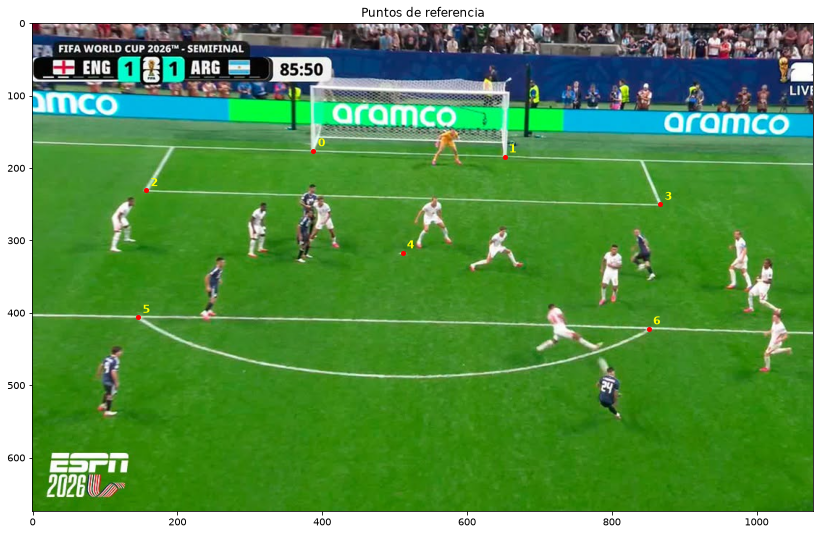

In [6]:
filepath_futbol = 'futbol'
img_gol = cv2.imread(f'{filepath_futbol}/test-gol-enzo.png')[:, :, ::-1]   # BGR -> RGB

# Puntos de referencia en la cancha (m)
objPts_gol = np.array([
    [0.0,  30.34],   # 0: palo izquierdo
    [0.0,  37.66],   # 1: palo derecho
    [5.5,  24.84],   # 2: área chica, esquina frontal izq
    [5.5,  43.16],   # 3: área chica, esquina frontal der
    [11.0, 34.0],    # 4: punto penal
    [16.5, 26.69],   # 5: medialuna ∩ línea del área, izq
    [16.5, 41.31],   # 6: medialuna ∩ línea del área, der
])

# Los mismos puntos en la foto (px)
imgPts_gol = np.array([
    [388.0, 176.0],
    [652.0, 184.5],
    [157.0, 231.0],
    [867.0, 250.0],
    [511.0, 317.0],
    [146.0, 406.0],
    [851.0, 422.0],
])

plt.figure(figsize=(14, 9))
plt.imshow(img_gol)
plt.plot(imgPts_gol[:, 0], imgPts_gol[:, 1], 'ro', markersize=4)
for i in range(imgPts_gol.shape[0]):
    plt.text(imgPts_gol[i, 0] + 6, imgPts_gol[i, 1] - 6, str(i), color='yellow', fontsize=11, weight='bold')
plt.title('Puntos de referencia')
plt.show()

**Estimación de $\mathbf{H}$.** Con las correspondencias resolvemos $Q\mathbf{h} = 0$ con $\texttt{resolverDLT2D}$ (DLT con normalización de Hartley, ejercicio 3). La $\mathbf{H}$ obtenida lleva puntos de la cancha a la imagen, y su inversa $\mathbf{H}^{-1}$ lleva puntos de la imagen a la cancha.

In [7]:
H_gol = alc.resolverDLT2D(imgPts_gol, objPts_gol)
H_gol_inv = alc.inversa(H_gol)
print(H_gol / H_gol[2, 2])

[[-9.53430567e+00  3.75647500e+01 -7.34465113e+02]
 [ 7.85950352e+00  1.32071533e+00  1.41846383e+02]
 [-1.67225457e-02  1.23844546e-03  1.00000000e+00]]


**Posición de Enzo.** Marcamos en la foto el pie de apoyo de Enzo al patear, $(u, v) = (810,\ 545)$, y lo llevamos a la cancha:

$$\begin{bmatrix} q_1 \\ q_2 \\ q_3 \end{bmatrix} = \mathbf{H}^{-1} \begin{bmatrix} 810 \\ 545 \\ 1 \end{bmatrix}, \qquad U = \frac{q_1}{q_3},\quad V = \frac{q_2}{q_3}.$$

**Distancia.** La distancia se mide respecto al arco, y el punto del arco es a elección (consultado en clase). Elegimos el punto donde entró la pelota, $(U, V) = (0,\ 31)$: sobre la línea de meta, entre los palos ($V = 30.34$ a $37.66$) y cerca del palo izquierdo. La distancia en línea recta sobre el piso es

$$d = \sqrt{(U_{enzo} - 0)^2 + (V_{enzo} - 31)^2}.$$

Enzo en la cancha: U = 22.24 m, V = 39.80 m
Distancia al arco (punto donde entró la pelota): 23.92 m


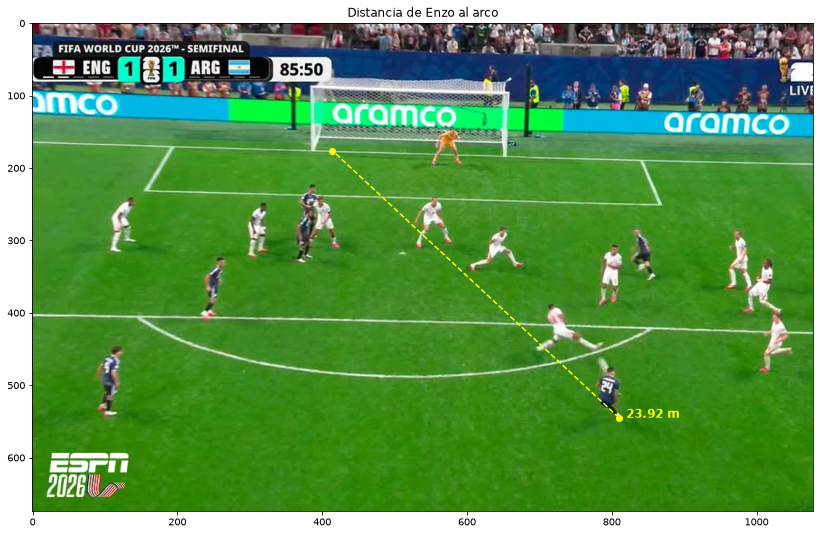

In [8]:
# Pie de apoyo de Enzo al patear (px)
pie_enzo_img = np.array([[810.0, 545.0]])
# Punto del arco donde entró la pelota (m)
punto_gol = np.array([0.0, 31.0])

U_enzo, V_enzo = alc.aplicarHomografia(H_gol_inv, pie_enzo_img)[0]
distancia = np.sqrt((U_enzo - punto_gol[0])**2 + (V_enzo - punto_gol[1])**2)
print(f'Enzo en la cancha: U = {U_enzo:.2f} m, V = {V_enzo:.2f} m')
print(f'Distancia al arco (punto donde entró la pelota): {distancia:.2f} m')

# Llevamos el punto del gol a la foto para dibujar el segmento
punto_gol_img = alc.aplicarHomografia(H_gol, np.array([punto_gol]))[0]

plt.figure(figsize=(14, 9))
plt.imshow(img_gol)
plt.plot([pie_enzo_img[0, 0], punto_gol_img[0]], [pie_enzo_img[0, 1], punto_gol_img[1]], '--o', color='yellow', linewidth=1.5, markersize=6)
plt.text(pie_enzo_img[0, 0] + 10, pie_enzo_img[0, 1], f'{distancia:.2f} m', color='yellow', fontsize=12, weight='bold')
plt.title('Distancia de Enzo al arco')
plt.show()

Enzo está en $U \approx 22.24$ m, $V \approx 39.80$ m, a $d \approx 23.92$ m del punto donde entró la pelota. El resultado es razonable: Enzo patea desde afuera del área grande ($U > 16.5$) y también por fuera de la medialuna ($U > 20.15$ en $V = 34$). Hay que tener en cuenta que el pie se marcó a mano y que Enzo está por debajo de los puntos de referencia, así que el resultado tiene una incertidumbre del orden de algunas décimas de metro.

b) Ubicar espacialmente todos los jugadores argentinos y dibujar un círculo de 1 metro de radio sobre el piso, como se muestra en la fig. 4. Para ello, definir el círculo en coordenadas de la cancha y proyectar sus puntos a la imagen mediante $\mathbf{H}$.

#### Resolución 4.b
Usamos la misma $\mathbf{H}$ del 4.a. Para cada jugador: llevamos su pie a la cancha con $\mathbf{H}^{-1}$, armamos ahí el círculo de 1 m de radio con $\texttt{circuloEnCancha}$ (sin seno ni coseno, despejando $V = V_0 \pm \sqrt{r^2 - (U - U_0)^2}$) y proyectamos sus puntos a la foto con $\mathbf{H}$.

Los pies se marcaron a mano. El jugador de atrás del grupo del medio tiene los pies tapados por su compañero, así que su posición se estimó por la bota que se ve y es la menos precisa.

Jugador 0: U = 22.53 m, V = 27.14 m
Jugador 1: U = 16.33 m, V = 28.65 m
Jugador 2: U = 9.79 m, V = 31.07 m
Jugador 3: U = 11.83 m, V = 30.94 m
Jugador 4: U = 12.59 m, V = 41.85 m
Jugador 5: U = 22.24 m, V = 39.80 m


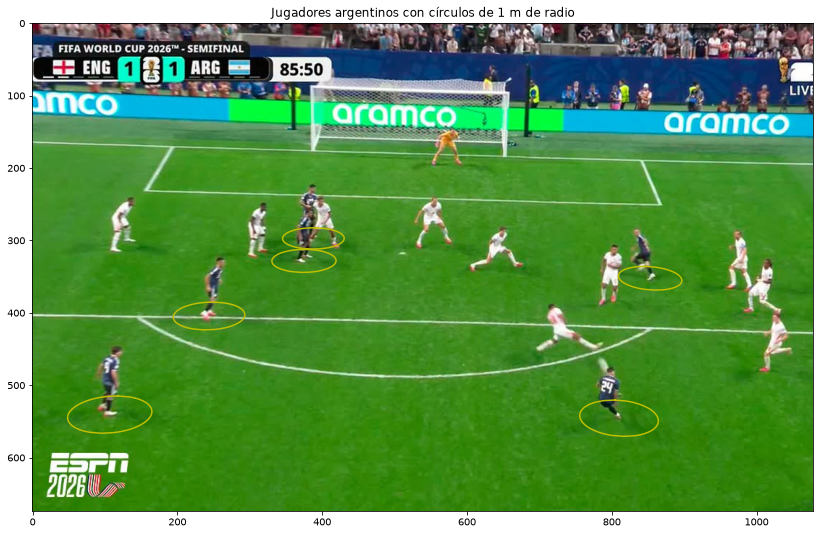

In [9]:
# Pies de los jugadores argentinos (px)
pies_argentinos_img = np.array([
    [107.0, 540.0],   # abajo a la izquierda
    [244.0, 404.0],   # sobre la línea del área
    [388.0, 297.0],   # el de atrás del grupo del medio (pies tapados, estimado)
    [375.0, 328.0],   # el de adelante del grupo del medio
    [853.0, 352.0],   # a la derecha
    [810.0, 545.0],   # Enzo
])

pies_cancha = alc.aplicarHomografia(H_gol_inv, pies_argentinos_img)
for i in range(pies_cancha.shape[0]):
    print(f'Jugador {i}: U = {pies_cancha[i, 0]:.2f} m, V = {pies_cancha[i, 1]:.2f} m')

plt.figure(figsize=(14, 9))
plt.imshow(img_gol)
for i in range(pies_cancha.shape[0]):
    circulo_img = alc.aplicarHomografia(H_gol, alc.circuloEnCancha(pies_cancha[i], 1.0, 50))
    plt.plot(circulo_img[:, 0], circulo_img[:, 1], 'y-', linewidth=1.5)
plt.title('Jugadores argentinos con círculos de 1 m de radio')
plt.show()

En la foto los círculos se ven como elipses por la perspectiva. El jugador que está sobre la línea del área (jugador 1) da $U \approx 16.33$ m, muy cerca del valor real $16.5$ m, lo que confirma que $\mathbf{H}$ funciona bien también fuera de los puntos de referencia.

Para la foto $\texttt{posibleoffside.jpg}$, estimar su propia homografía $\mathbf{H}$ y utilizarla para:

c) Trazar una recta paralela a la línea de fondo de la cancha que toque el pie del último defensor (es decir, el penúltimo jugador adversario, contando al arquero) para determinar si los jugadores de blanco estaban en fuera de juego. La recta se define en coordenadas de la cancha y se proyecta a la imagen mediante $\mathbf{H}$.

#### Resolución 4.c
Es otra foto (otra cámara), así que estimamos una homografía nueva $\mathbf{H}$ con puntos de esta imagen. Usamos el mismo sistema de coordenadas del plano: los de blanco atacan el arco de $U = 105$ (a la derecha de la foto) y la banda de arriba de la foto es $V = 68$.

Puntos de referencia: el córner $(105, 68)$, las esquinas del área grande sobre la línea del área $(88.5,\ 34 \pm 20.16)$, las esquinas frontales del área chica $(99.5,\ 34 \pm 9.16)$, el punto penal $(94, 34)$ y el corte de abajo de la medialuna con la línea del área $(88.5,\ 26.69)$. El corte de arriba está tapado por jugadores.

In [10]:
img_offside = cv2.imread(f'{filepath_futbol}/test-fuera-de-juego.png')[:, :, ::-1]   # BGR -> RGB

# Puntos de referencia en la cancha (m)
objPts_offside = np.array([
    [105.0, 68.0],    # 0: córner (banderín)
    [88.5,  54.16],   # 1: área grande, esquina de arriba sobre la línea del área
    [88.5,  13.84],   # 2: área grande, esquina de abajo sobre la línea del área
    [99.5,  43.16],   # 3: área chica, esquina frontal de arriba
    [99.5,  24.84],   # 4: área chica, esquina frontal de abajo
    [94.0,  34.0],    # 5: punto penal
    [88.5,  26.69],   # 6: medialuna ∩ línea del área, abajo
])

# Los mismos puntos en la foto (px)
imgPts_offside = np.array([
    [1306.0, 237.0],
    [736.0,  317.0],
    [735.5,  756.5],
    [1230.0, 390.0],
    [1365.0, 576.0],
    [1008.0, 474.0],
    [734.0,  557.0],
])

H_off = alc.resolverDLT2D(imgPts_offside, objPts_offside)
H_off_inv = alc.inversa(H_off)
print(H_off / H_off[2, 2])

[[ 8.86024888e+01  1.75955968e+01 -7.13755177e+03]
 [-9.39970857e-01 -6.46638105e+00  1.14738130e+03]
 [-4.25814054e-04  2.38092452e-02  1.00000000e+00]]


**Último defensor.** Llevamos a la cancha con $\mathbf{H}^{-1}$ el pie más adelantado (hacia el arco) de cada defensor. El último defensor es el penúltimo contando al arquero: el de mayor $U$ sin contar al arquero, que es el de mayor $U$ de todos.

In [11]:
# Pie más adelantado de cada defensor (px)
pies_defensores_img = np.array([
    [1432.0, 467.0],  # arquero
    [824.0,  331.0],  # el de arriba del grupo
    [767.0,  370.0],  # el del medio del grupo
    [770.0,  535.0],  # el 5
    [813.0,  560.0],  # el 22
])

U_defensores = alc.aplicarHomografia(H_off_inv, pies_defensores_img)[:, 0]

# El arquero es el de mayor U; el último defensor, el de mayor U entre los demás
i_arquero = 0
for i in range(U_defensores.shape[0]):
    if U_defensores[i] > U_defensores[i_arquero]:
        i_arquero = i
i_ultimo = -1
for i in range(U_defensores.shape[0]):
    if i != i_arquero and (i_ultimo == -1 or U_defensores[i] > U_defensores[i_ultimo]):
        i_ultimo = i
U_ultimo = U_defensores[i_ultimo]
for i in range(U_defensores.shape[0]):
    print(f'Defensor {i}: U = {U_defensores[i]:.2f} m')
print(f'Último defensor: {i_ultimo}, U = {U_ultimo:.2f} m')

Defensor 0: U = 102.42 m
Defensor 1: U = 90.68 m
Defensor 2: U = 89.23 m
Defensor 3: U = 89.16 m
Defensor 4: U = 89.91 m
Último defensor: 1, U = 90.68 m


**Atacantes y recta del último defensor.** Un atacante está adelantado si su pie tiene $U$ mayor que el del último defensor. La recta paralela a la línea de fondo es $U = U_{\text{último}}$; la definimos en la cancha y la proyectamos con $\mathbf{H}$.

Atacante 0: U = 89.83 m, diferencia = -0.85 m -> habilitado
Atacante 1: U = 89.55 m, diferencia = -1.13 m -> habilitado
Atacante 2: U = 90.24 m, diferencia = -0.44 m -> habilitado
Atacante 3: U = 91.00 m, diferencia = +0.32 m -> ADELANTADO
Atacante 4: U = 90.87 m, diferencia = +0.19 m -> ADELANTADO


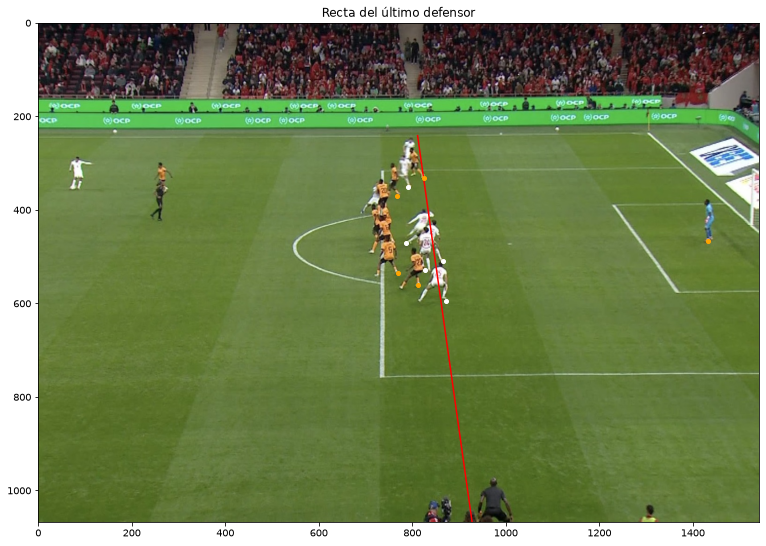

In [12]:
# Pie más adelantado de cada atacante (px)
pies_atacantes_img = np.array([
    [791.0, 350.0],   # el de arriba del grupo
    [787.0, 470.0],   # el del medio
    [828.0, 528.0],   # el 24
    [866.0, 509.0],   # el que está a la derecha del 24 (pie posiblemente en el aire)
    [872.0, 594.0],   # el 25
])

U_atacantes = alc.aplicarHomografia(H_off_inv, pies_atacantes_img)[:, 0]
for i in range(U_atacantes.shape[0]):
    diferencia = U_atacantes[i] - U_ultimo
    estado = 'ADELANTADO' if diferencia > 0 else 'habilitado'
    print(f'Atacante {i}: U = {U_atacantes[i]:.2f} m, diferencia = {diferencia:+.2f} m -> {estado}')

recta_img = alc.aplicarHomografia(H_off, np.array([[U_ultimo, 0.0], [U_ultimo, 68.0]]))

plt.figure(figsize=(14, 9))
plt.imshow(img_offside)
plt.plot(recta_img[:, 0], recta_img[:, 1], 'r-', linewidth=1.5)
plt.plot(pies_defensores_img[:, 0], pies_defensores_img[:, 1], 'o', color='orange', markersize=4)
plt.plot(pies_atacantes_img[:, 0], pies_atacantes_img[:, 1], 'wo', markersize=4)
plt.xlim(0, img_offside.shape[1])
plt.ylim(img_offside.shape[0], 0)
plt.title('Recta del último defensor')
plt.show()

**Conclusión.** El último defensor es el de arriba del grupo ($U \approx 90.68$ m). Dos atacantes quedan por delante de la recta: el que está a la derecha del 24 ($+0.32$ m) y el 25 ($+0.19$ m), así que **hay fuera de juego**. La pelota está muy atrás (la tiene el jugador de la izquierda), así que esa condición también se cumple.

La jugada es muy ajustada: las diferencias son de unos pocos decímetros, del mismo orden que el error de marcar los pies a mano. Además, el pie del atacante a la derecha del 24 parece estar en el aire, y $\mathbf{H}$ solo vale para puntos sobre el piso.

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

---